# 05 — Simple model

## Train/test split

- 80% train, 20% test, fixed seed.
- Same planet/false-positive ratio on both sides.
- All KOIs from one star stay on the same side, so the test set only has stars the model has never seen.

The split is saved to `data/split.csv` so the CNN uses exactly the same one.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

DATA = Path("../data")
SEED = 42

names = pd.read_csv(DATA / "kepler_names.csv")
X_global = np.load(DATA / "kepler_global.npy")
X_local = np.load(DATA / "kepler_local.npy")
y = np.load(DATA / "kepler_y.npy")
assert len(names) == len(y) == len(X_global) == len(X_local)
assert (names["label"].values == y).all()

## Split

In [2]:
# 5 folds -> each fold is ~20%. Take the first as the test set.
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(sgkf.split(X_global, y, groups=names["kepid"]))

split = names[["kepoi_name", "kepid", "label"]].copy()
split["split"] = "train"
split.loc[test_idx, "split"] = "test"
split.to_csv(DATA / "split.csv", index=False)

## Check

In [3]:
summary = split.groupby("split").agg(
    signals=("label", "size"),
    planets=("label", "sum"),
    stars=("kepid", "nunique"),
)
summary["false_positives"] = summary["signals"] - summary["planets"]
summary["% of signals"] = (100 * summary["signals"] / len(split)).round(1)
summary["% planets"] = (100 * summary["planets"] / summary["signals"]).round(1)
display(summary)

train_stars = set(split.loc[split.split == "train", "kepid"])
test_stars = set(split.loc[split.split == "test", "kepid"])
print("stars on both sides:", len(train_stars & test_stars))
assert not train_stars & test_stars

,signals,planets,stars,false_positives,% of signals,% planets
split,,,,,,
test,159,80,154,79,20.0,50.3
train,637,319,617,318,80.0,50.1


stars on both sides: 0


## Load the split (use this in later notebooks)

In [4]:
is_train = (split["split"] == "train").values
Xg_train, Xg_test = X_global[is_train], X_global[~is_train]
Xl_train, Xl_test = X_local[is_train], X_local[~is_train]
y_train, y_test = y[is_train], y[~is_train]
print("train:", Xg_train.shape, " test:", Xg_test.shape)

train: (637, 201)  test: (159, 201)


In [5]:
import pandas as pd
split = pd.read_csv("../data/split.csv")
print(split.head())
print(split.columns)

  kepoi_name     kepid  label  split
0  K02086.01   6768394      1  train
1  K04304.01  11612280      1   test
2  K03127.01   9907129      1  train
3  K02820.01  11963206      1  train
4  K04009.01   8934103      1  train
Index(['kepoi_name', 'kepid', 'label', 'split'], dtype='object')


In [6]:
koi = pd.read_csv("../data/kepler_selected.csv")
print(koi.shape)
#merge two tables
data = pd.merge(split, koi, on=["kepoi_name", "kepid"])
print(data.shape)
print(data.head())
#split into train and test
train_df = data[data["split"] == "train"]
test_df = data[data["split"] == "test"]
print(len(train_df), len(test_df))
#Pull out X and y as NumPy arrays (X is the inputs (one row per signal, 3 numbers each). y is the answers (1 = planet, 0 = fake).)
features = ["koi_depth", "koi_duration", "koi_period"]

X_train = train_df[features].to_numpy()
X_test = test_df[features].to_numpy()
y_train = train_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

print(X_train.shape, X_test.shape)
print(y_train.shape, y_test.shape)
print("planets in train:", y_train.sum(), "| planets in test:", y_test.sum())

(800, 9)
(796, 11)
  kepoi_name     kepid  label  split koi_disposition  koi_period  koi_time0bk  \
0  K02086.01   6768394      1  train       CONFIRMED    7.132947    135.99259   
1  K04304.01  11612280      1   test       CONFIRMED    9.406136    137.70730   
2  K03127.01   9907129      1  train       CONFIRMED    9.705693    140.37090   
3  K02820.01  11963206      1  train       CONFIRMED    3.009125    131.62696   
4  K04009.01   8934103      1  train       CONFIRMED  175.138920    296.03778   

   koi_duration  koi_depth  koi_srad  koi_prad  
0         4.368      145.0     1.307      1.64  
1         4.882       79.5     1.268      1.14  
2         7.702      140.8     1.385      2.07  
3         2.228      191.4     0.893      1.22  
4        10.767      634.5     1.241      3.06  
637 159
(637, 3) (159, 3)
(637,) (159,)
planets in train: 319 | planets in test: 80


In [7]:
#Scaling the features: 1. take log 10 of the data which squashes the big numbers and makes the range suitable. 2. Then we standardise z = (x − μ) ÷ σ
import numpy as np

# a. log10 of every feature
X_train_log = np.log10(X_train)
X_test_log = np.log10(X_test)

# b. mean and spread of each column, from TRAINING data only
mu = X_train_log.mean(axis=0)
sigma = X_train_log.std(axis=0)

X_train_s = (X_train_log - mu) / sigma
X_test_s = (X_test_log - mu) / sigma

print("mu:", mu)
print("sigma:", sigma)
print("train mean after scaling:", X_train_s.mean(axis=0).round(3))
print("train std after scaling:", X_train_s.std(axis=0).round(3))

mu: [2.92018484 0.58610552 0.98349523]
sigma: [0.99151791 0.31901336 0.76320467]
train mean after scaling: [0. 0. 0.]
train std after scaling: [1. 1. 1.]


In [8]:
#Sigmoid function: squashes any number into a probability between 0 and 1
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# test it
for z in [-5, -1, 0, 1, 5]:
    print(z, "->", round(sigmoid(z), 3))

-5 -> 0.007
-1 -> 0.269
0 -> 0.5
1 -> 0.731
5 -> 0.993


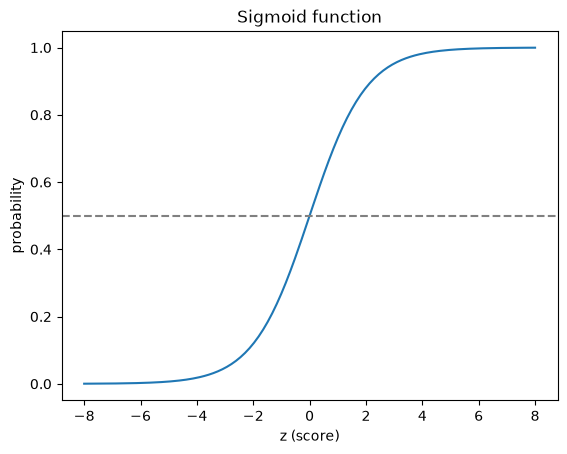

In [9]:
import matplotlib.pyplot as plt
z = np.linspace(-8, 8, 200)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, linestyle="--", color="gray")
plt.xlabel("z (score)"); plt.ylabel("probability")
plt.title("Sigmoid function")
plt.show()

In [10]:
#Loss function - Measures how wrong the prediction is - training attempts to make this value as small as possible
def loss_fn(y, p):
    eps = 1e-12                      # tiny number so we never take log(0)
    p = np.clip(p, eps, 1 - eps)    #keeps p strictly between 0 and 1, because log(0) is minus infinity and would break everything.
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))           #averages the loss over all signals.

# test it: true answer is a planet (y = 1)
for p in [0.99, 0.7, 0.5, 0.1, 0.01]:
    print(f"p = {p} -> loss = {loss_fn(np.array([1]), np.array([p])):.3f}")

p = 0.99 -> loss = 0.010
p = 0.7 -> loss = 0.357
p = 0.5 -> loss = 0.693
p = 0.1 -> loss = 2.303
p = 0.01 -> loss = 4.605


weights (depth, duration, period): [-0.525 -0.506  0.639]
bias: -0.026
first loss: 0.693 | final loss: 0.634


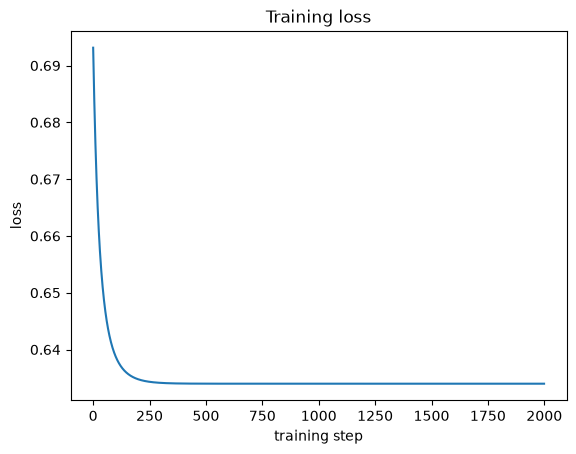

In [11]:
# ---- Setup: the model's starting point ----
w = np.zeros(3)      # 3 weights (depth, duration, period), all start at 0 = "no opinion yet"
b = 0.0              # bias: a starting nudge towards planet or fake, also 0
lr = 0.1             # learning rate: how big each correction step is
n = len(y_train)     # number of training signals (637), used to average
losses = []          # store the loss at each step so we can plot it later

# ---- Training: repeat guess -> measure -> correct, 2000 times ----
for step in range(2000):

    # STEP 1: GUESS
    # score each signal: z = w1*depth + w2*duration + w3*period + b (for all 637 at once)
    z = X_train_s @ w + b
    # turn each score into a probability of "planet" (0 to 1)
    p = sigmoid(z)

    # STEP 2: MEASURE HOW WRONG
    # average penalty across all signals (0 = perfect, 0.693 = coin flip)
    losses.append(loss_fn(y_train, p))

    # STEP 3: WORK OUT WHICH WAY TO FIX IT (the gradient)
    # how far off each guess was: positive = guessed too high, negative = too low
    error = p - y_train
    # gradient for each weight: (p - y) * x, averaged over all signals
    grad_w = X_train_s.T @ error / n
    # gradient for the bias: just the average error
    grad_b = error.mean()

    # STEP 4: UPDATE (take a small step downhill)
    # gradient points uphill (more wrong), so subtract it to become less wrong
    w = w - lr * grad_w
    b = b - lr * grad_b

# ---- Results ----
print("weights (depth, duration, period):", w.round(3))   # what the model learned
print("bias:", round(b, 3))
print("first loss:", round(losses[0], 3), "| final loss:", round(losses[-1], 3))

# plot the loss over training: it should start at 0.693 and go down, then flatten
plt.plot(losses)
plt.xlabel("training step"); plt.ylabel("loss")
plt.title("Training loss")
plt.show()

In [12]:
# ---- Predict on the TEST set (data the model has never seen) ----
p_test = sigmoid(X_test_s @ w + b)        # probability of "planet" for each test signal
pred = (p_test >= 0.5).astype(int)         # 0.5 or more -> predict planet (1), else fake (0)

# ---- Count the 4 possible outcomes ----
TP = np.sum((pred == 1) & (y_test == 1))   # said planet, was planet   (correct)
FP = np.sum((pred == 1) & (y_test == 0))   # said planet, was fake     (false alarm)
FN = np.sum((pred == 0) & (y_test == 1))   # said fake, was planet     (missed planet)
TN = np.sum((pred == 0) & (y_test == 0))   # said fake, was fake       (correct)

# ---- Scores ----
accuracy = (TP + TN) / len(y_test)         # fraction of all answers that were right
precision = TP / (TP + FP)                 # when it says "planet", how often is it right?
recall = TP / (TP + FN)                    # of all real planets, how many did it find?

print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}")
print(f"accuracy:  {accuracy:.3f}")
print(f"precision: {precision:.3f}")
print(f"recall:    {recall:.3f}")

TP=71  FP=26  FN=9  TN=53
accuracy:  0.780
precision: 0.732
recall:    0.887


## Compare with scikit-learn

Same scaled data. `C=np.inf` turns off scikit-learn's default regularisation, so it fits the same model as the code above.

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score

sk = LogisticRegression(C=np.inf).fit(X_train_s, y_train)
w_sk, b_sk = sk.coef_[0], sk.intercept_[0]
pred_sk = sk.predict(X_test_s)

comparison = pd.DataFrame({
    "mine": [*w, b, losses[-1], accuracy, precision, recall],
    "scikit-learn": [*w_sk, b_sk, loss_fn(y_train, sk.predict_proba(X_train_s)[:, 1]),
                     accuracy_score(y_test, pred_sk), precision_score(y_test, pred_sk), recall_score(y_test, pred_sk)],
}, index=["w_depth", "w_duration", "w_period", "bias", "train loss", "test accuracy", "test precision", "test recall"])
comparison.round(3)

,mine,scikit-learn
w_depth,-0.525,-0.525
w_duration,-0.506,-0.506
w_period,0.639,0.639
bias,-0.026,-0.026
train loss,0.634,0.634
test accuracy,0.780,0.780
test precision,0.732,0.732
test recall,0.888,0.888


## Confusion matrices

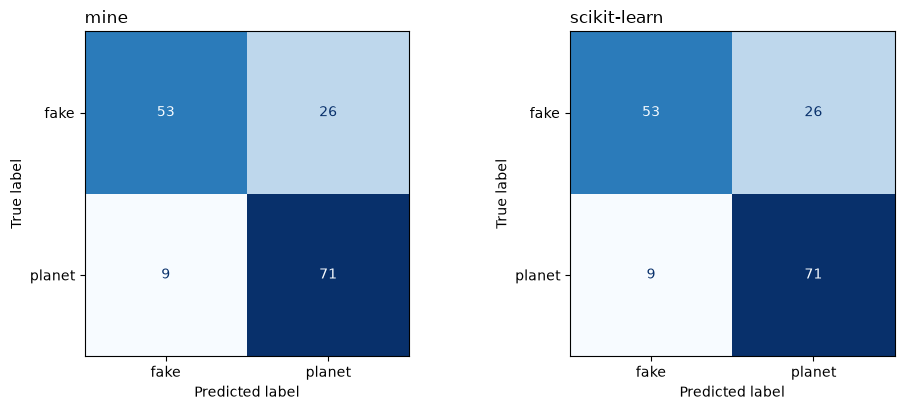

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (name, pr) in zip(axes, [("mine", pred), ("scikit-learn", pred_sk)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pr), display_labels=["fake", "planet"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, loc="left")
fig.tight_layout()
fig.savefig("../results/simple_model_confusion.png", dpi=150)
plt.show()

## Save

In [15]:
RESULTS = Path("../results")

# scores for both models
scores = comparison.T
for name, pr in [("mine", pred), ("scikit-learn", pred_sk)]:
    tn, fp, fn, tp = confusion_matrix(y_test, pr).ravel()
    scores.loc[name, ["TP", "FP", "FN", "TN"]] = [tp, fp, fn, tn]
scores[["TP", "FP", "FN", "TN"]] = scores[["TP", "FP", "FN", "TN"]].astype(int)
scores.index.name = "model"
scores.to_csv(RESULTS / "simple_model_scores.csv")

# my model, for reuse on TESS (feature order: depth, duration, period; log10 then (x - mu) / sigma)
np.savez(RESULTS / "simple_model.npz", w=w, b=b, mu=mu, sigma=sigma, features=np.array(features))
scores

,w_depth,w_duration,w_period,bias,train loss,test accuracy,test precision,test recall,TP,FP,FN,TN
model,,,,,,,,,,,,
mine,-0.525196,-0.506108,0.638535,-0.025731,0.633987,0.779874,0.731959,0.8875,71,26,9,53
scikit-learn,-0.525201,-0.506101,0.638599,-0.025641,0.633987,0.779874,0.731959,0.8875,71,26,9,53
